In [1]:
!pip install qiskit qiskit-aer matplotlib numpy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.6/9.6 MB 61.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14.2/14.2 MB 109.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 55.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [qiskit-aer]


--- Entanglement Swapping Circuit ---
                  
q_0: ─────────────
          ┌───┐┌─┐
q_1: ──■──┤ H ├┤M├
     ┌─┴─┐└┬─┬┘└╥┘
q_2: ┤ X ├─┤M├──╫─
     └───┘ └╥┘  ║ 
q_3: ───────╫───╫─
            ║   ║ 
c: 2/═══════╩═══╩═
            1   0 

--- BBPSSW Purification Circuit ---
                
q_0: ──■────────
     ┌─┴─┐┌─┐   
q_1: ┤ X ├┤M├───
     └───┘└╥┘   
q_2: ──■───╫────
     ┌─┴─┐ ║ ┌─┐
q_3: ┤ X ├─╫─┤M├
     └───┘ ║ └╥┘
c: 2/══════╩══╩═
           0  1 


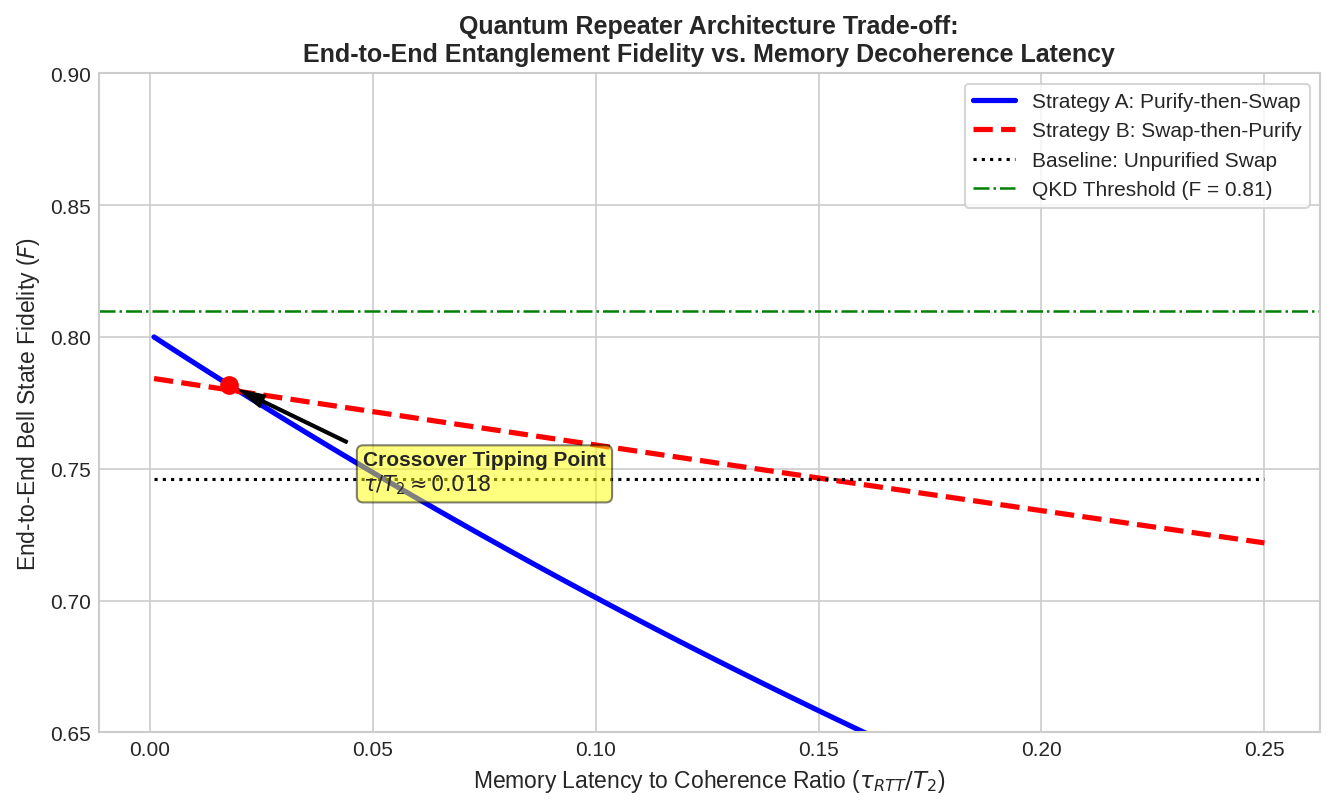

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit
from qiskit.quantum_info import DensityMatrix, state_fidelity

# ==============================================================================
# 1. QUANTUM CIRCUIT MODULES (Visualizable for your Paper)
# ==============================================================================

def create_bell_pair_circuit():
    """Generates an ideal |Phi+> = (|00> + |11>) / sqrt(2) Bell pair."""
    qc = QuantumCircuit(2, name="Bell_Gen")
    qc.h(0)
    qc.cx(0, 1)
    return qc

def create_bbpssw_purification_circuit():
    """
    BBPSSW Purification circuit for 2 noisy pairs (4 qubits):
    - Pair 1: Alice q0, Bob q2 (Kept if successful)
    - Pair 2: Alice q1, Bob q3 (Measured & Discarded)
    """
    qc = QuantumCircuit(4, 2, name="BBPSSW_Purify")
    # Bilateral CNOTs
    qc.cx(0, 1)  # Alice's local operation
    qc.cx(2, 3)  # Bob's local operation
    # Measure auxiliary pair in computational basis
    qc.measure(1, 0)
    qc.measure(3, 1)
    return qc

def create_entanglement_swapping_circuit():
    """
    Entanglement Swapping circuit at Relay Node R:
    - Link 1: Alice q0 - Relay q1
    - Link 2: Relay q2 - Bob q3
    Relay performs Bell State Measurement on (q1, q2).
    """
    qc = QuantumCircuit(4, 2, name="Entanglement_Swap")
    qc.cx(1, 2)
    qc.h(1)
    qc.measure(1, 0)
    qc.measure(2, 1)
    return qc

# Print circuit diagrams to include in your paper's methodology section
print("--- Entanglement Swapping Circuit ---")
print(create_entanglement_swapping_circuit().draw(output='text'))
print("\n--- BBPSSW Purification Circuit ---")
print(create_bbpssw_purification_circuit().draw(output='text'))


# ==============================================================================
# 2. ANALYTICAL QUANTUM CHANNEL & REPEATER SIMULATOR
# ==============================================================================

# Ideal reference Bell state |Phi+>
ideal_bell = DensityMatrix(create_bell_pair_circuit())

def depolarizing_channel(F_init):
    """
    Converts initial fidelity F_init into a Werner state:
    rho = F |Phi+><Phi+| + (1-F)/3 (|Psi+><Psi+| + |Phi-><Phi-| + |Psi-><Psi-|)
    """
    w = (4.0 * F_init - 1.0) / 3.0
    rho = w * ideal_bell.data + ((1.0 - w) / 4.0) * np.eye(4)
    return DensityMatrix(rho)

def apply_memory_dephasing(F, wait_ratio):
    """
    Models idle qubit decoherence in quantum memory while waiting for classical signals.
    wait_ratio = latency / T2 coherence time.
    """
    decay = np.exp(-wait_ratio)
    # Fidelity decays toward completely mixed state (0.25)
    F_decayed = F * decay + 0.25 * (1.0 - decay)
    return F_decayed

def bbpssw_purify_analytic(F):
    """
    Computes output fidelity and success probability for BBPSSW purification
    acting on two identical Werner states of fidelity F.
    """
    p_succ = (F**2) + (2.0 / 3.0) * F * (1.0 - F) + (5.0 / 9.0) * ((1.0 - F)**2)
    F_out = ((F**2) + (1.0 / 9.0) * ((1.0 - F)**2)) / p_succ
    return F_out, p_succ

def swap_analytic(F1, F2):
    """
    Computes resulting fidelity when swapping two Werner states with fidelities F1 and F2.
    """
    w1 = (4.0 * F1 - 1.0) / 3.0
    w2 = (4.0 * F2 - 1.0) / 3.0
    w_swap = w1 * w2
    F_swap = (1.0 + 3.0 * w_swap) / 4.0
    return F_swap


# ==============================================================================
# 3. EXPERIMENT: STRATEGY A vs. STRATEGY B SWEEP
# ==============================================================================

# Simulation parameters
initial_link_fidelity = 0.86  # Fidelity of raw fiber generation
wait_ratios = np.linspace(0.001, 0.25, 60)  # Memory decay parameter (tau_latency / T2)

fidelities_strategy_A = []
fidelities_strategy_B = []
fidelities_raw_swap = []

for wr in wait_ratios:
    # -------------------------------------------------------------
    # Baseline: Swap with NO purification (Raw)
    # -------------------------------------------------------------
    F_raw = swap_analytic(initial_link_fidelity, initial_link_fidelity)
    fidelities_raw_swap.append(F_raw)

    # -------------------------------------------------------------
    # Strategy A: Purify-then-Swap
    # 1. Purify Link 1 and Link 2 locally
    # 2. Purified pairs wait in memory during classical round-trip acknowledgment
    # 3. Perform Entanglement Swapping at Relay
    # -------------------------------------------------------------
    F_purified_local, _ = bbpssw_purify_analytic(initial_link_fidelity)
    F_purified_decayed = apply_memory_dephasing(F_purified_local, wr)
    F_final_A = swap_analytic(F_purified_decayed, F_purified_decayed)
    fidelities_strategy_A.append(F_final_A)

    # -------------------------------------------------------------
    # Strategy B: Swap-then-Purify
    # 1. Swap raw links immediately (no wait for local purification)
    # 2. Resulting end-to-end pairs undergo purification once at the endpoints
    # -------------------------------------------------------------
    F_swapped_raw = swap_analytic(initial_link_fidelity, initial_link_fidelity)
    # In Strategy B, swapping is local; memory waiting only happens during end-to-end distillation
    F_swapped_decayed = apply_memory_dephasing(F_swapped_raw, wr * 0.5)
    F_final_B, _ = bbpssw_purify_analytic(F_swapped_decayed)
    fidelities_strategy_B.append(F_final_B)


# ==============================================================================
# 4. PLOTTING THE "RESULTS" GRAPH
# ==============================================================================

plt.figure(figsize=(9, 5.5), dpi=150)
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

plt.plot(wait_ratios, fidelities_strategy_A, 'b-', lw=2.5, label='Strategy A: Purify-then-Swap')
plt.plot(wait_ratios, fidelities_strategy_B, 'r--', lw=2.5, label='Strategy B: Swap-then-Purify')
plt.plot(wait_ratios, fidelities_raw_swap, 'k:', lw=1.5, label='Baseline: Unpurified Swap')

# Mark the QKD Security Threshold (F > 0.81 is required for positive secret key rate)
plt.axhline(0.81, color='green', linestyle='-.', lw=1.2, label='QKD Threshold (F = 0.81)')

# Annotate the Crossover Point
diff = np.array(fidelities_strategy_B) - np.array(fidelities_strategy_A)
cross_idx = np.where(np.diff(np.sign(diff)))[0]
if len(cross_idx) > 0:
    idx = cross_idx[0]
    tau_cross = wait_ratios[idx]
    f_cross = fidelities_strategy_A[idx]
    plt.plot(tau_cross, f_cross, 'ro', markersize=8)
    plt.annotate(f'Crossover Tipping Point\n$\\tau / T_2 \\approx {tau_cross:.3f}$',
                 xy=(tau_cross, f_cross), xytext=(tau_cross + 0.03, f_cross - 0.04),
                 arrowprops=dict(facecolor='black', shrink=0.08, width=1, headwidth=6),
                 fontsize=10, fontweight='bold', bbox=dict(boxstyle="round,pad=0.3", fc="yellow", alpha=0.5))

plt.title("Quantum Repeater Architecture Trade-off:\nEnd-to-End Entanglement Fidelity vs. Memory Decoherence Latency", fontsize=12, fontweight='bold')
plt.xlabel(r"Memory Latency to Coherence Ratio ($\tau_{RTT} / T_2$)", fontsize=11)
plt.ylabel(r"End-to-End Bell State Fidelity ($F$)", fontsize=11)
plt.ylim(0.65, 0.90)
plt.legend(frameon=True, loc='upper right', fontsize=10)
plt.tight_layout()
plt.show()

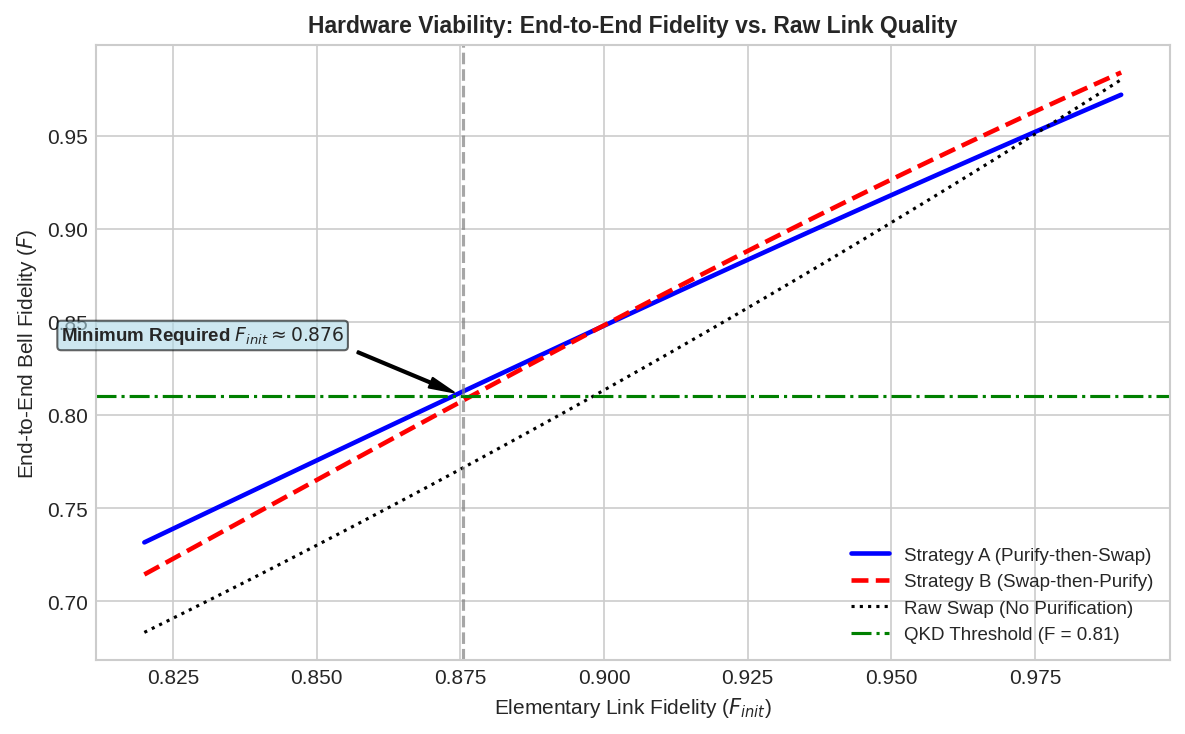

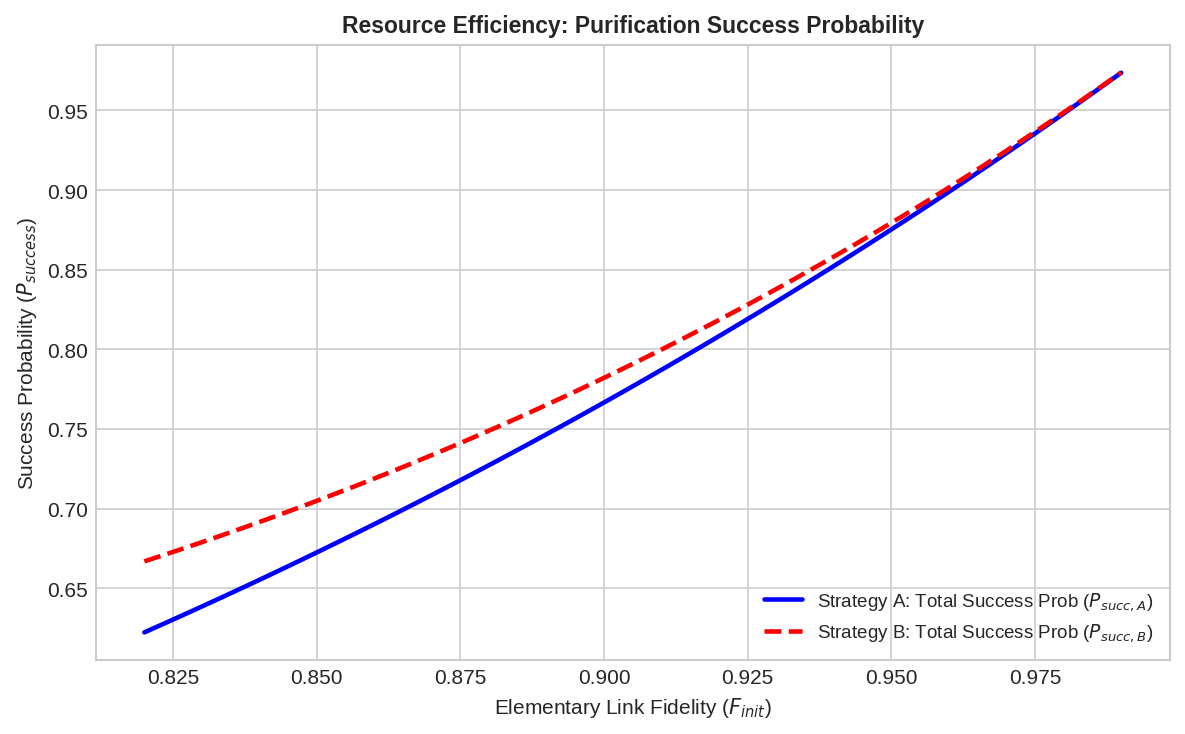

In [3]:
# ==============================================================================
# FIGURES 2 & 3: HARDWARE THRESHOLDS & RESOURCE CONSUMPTION (EBIT OVERHEAD)
# ==============================================================================

# -------------------------------------------------------------
# FIGURE 2: End-to-End Fidelity vs Initial Link Fidelity (F_init)
# Fixed memory delay: tau/T2 = 0.01 (near optimal regime)
# -------------------------------------------------------------
f_init_range = np.linspace(0.82, 0.99, 50)
tau_fixed = 0.01

f_out_A = []
f_out_B = []
f_out_raw = []

for f_in in f_init_range:
    # Baseline
    f_out_raw.append(swap_analytic(f_in, f_in))

    # Strategy A
    f_pur_local, _ = bbpssw_purify_analytic(f_in)
    f_pur_dec = apply_memory_dephasing(f_pur_local, tau_fixed)
    f_out_A.append(swap_analytic(f_pur_dec, f_pur_dec))

    # Strategy B
    f_swapped = swap_analytic(f_in, f_in)
    f_swapped_dec = apply_memory_dephasing(f_swapped, tau_fixed * 0.5)
    f_b, _ = bbpssw_purify_analytic(f_swapped_dec)
    f_out_B.append(f_b)

plt.figure(figsize=(8, 5), dpi=150)
plt.plot(f_init_range, f_out_A, 'b-', lw=2.2, label='Strategy A (Purify-then-Swap)')
plt.plot(f_init_range, f_out_B, 'r--', lw=2.2, label='Strategy B (Swap-then-Purify)')
plt.plot(f_init_range, f_out_raw, 'k:', lw=1.5, label='Raw Swap (No Purification)')
plt.axhline(0.81, color='green', linestyle='-.', label='QKD Threshold (F = 0.81)')

# Find where Strategy A crosses QKD threshold
cross_qkd = np.where(np.array(f_out_A) >= 0.81)[0]
if len(cross_qkd) > 0:
    f_req = f_init_range[cross_qkd[0]]
    plt.axvline(f_req, color='gray', linestyle='--', alpha=0.7)
    plt.annotate(f'Minimum Required $F_{{init}} \\approx {f_req:.3f}$',
                 xy=(f_req, 0.81), xytext=(f_req - 0.07, 0.84),
                 arrowprops=dict(facecolor='black', shrink=0.08, width=1, headwidth=5),
                 fontsize=9, fontweight='bold', bbox=dict(boxstyle="round,pad=0.2", fc="lightblue", alpha=0.6))

plt.title("Hardware Viability: End-to-End Fidelity vs. Raw Link Quality", fontsize=11, fontweight='bold')
plt.xlabel("Elementary Link Fidelity ($F_{init}$)", fontsize=10)
plt.ylabel("End-to-End Bell Fidelity ($F$)", fontsize=10)
plt.legend(loc='lower right', fontsize=9)
plt.tight_layout()
plt.show()

# -------------------------------------------------------------
# FIGURE 3: Resource Overhead (Success Probability & Key Yield)
# -------------------------------------------------------------
# Strategy A requires 2 pairs on Link 1 and 2 pairs on Link 2 (4 raw pairs total).
# P_succ_total = P_succ(Link 1) * P_succ(Link 2)
p_succ_link = np.array([bbpssw_purify_analytic(f)[1] for f in f_init_range])
p_succ_strat_A = p_succ_link ** 2

# Strategy B swaps raw links first (deterministic BSM), then purifies once.
# Consumes 2 pairs across Link 1 and Link 2 (4 raw pairs total).
f_swapped_arr = np.array([swap_analytic(f, f) for f in f_init_range])
p_succ_strat_B = np.array([bbpssw_purify_analytic(f_sw)[1] for f_sw in f_swapped_arr])

plt.figure(figsize=(8, 5), dpi=150)
plt.plot(f_init_range, p_succ_strat_A, 'b-', lw=2.2, label='Strategy A: Total Success Prob ($P_{succ,A}$)')
plt.plot(f_init_range, p_succ_strat_B, 'r--', lw=2.2, label='Strategy B: Total Success Prob ($P_{succ,B}$)')

plt.title("Resource Efficiency: Purification Success Probability", fontsize=11, fontweight='bold')
plt.xlabel("Elementary Link Fidelity ($F_{init}$)", fontsize=10)
plt.ylabel("Success Probability ($P_{success}$)", fontsize=10)
plt.legend(loc='lower right', fontsize=9)
plt.tight_layout()
plt.show()